# RNN 실습 2: 사인파 다음 값 예측 (RNN)

| 순서 | 내용 | 시간 |
|---|---|---|
| 1 | 사인파 데이터와 윈도우 만들기 | 5분 |
| 2 | `nn.RNN` 입력·출력 모양(shape) 익히기 | 5분 |
| 3 | RNN 모델 만들고 학습 | 10분 |
| 4 | 예측 결과 그래프 | 3분 |
| 5 | 문제 (코드를 직접 고쳐 보기) | 남는 시간·과제 |

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(0)

## 1. 사인파 다음 값 예측 (many-to-one)
- 데이터: $\sin$ 곡선 위의 점 1,000개
- 문제: **지난 20개 값 → 다음 1개 값** (회귀라서 손실 함수는 MSE)
- 모델: RNN(hidden 16) → 마지막 h → Linear(16 → 1)

X: (980, 20, 1)  y: (980, 1)


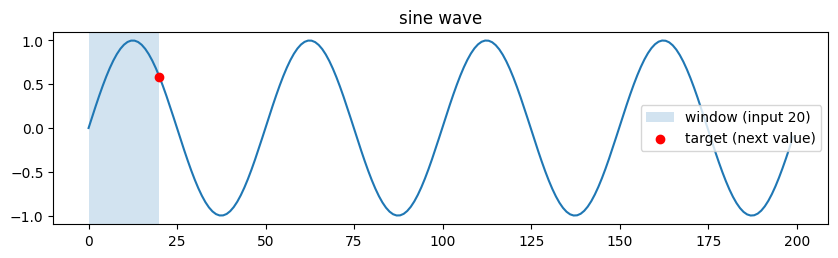

In [2]:
t = torch.linspace(0, 40 * torch.pi, 1000)
wave = torch.sin(t)

WINDOW = 20
X = torch.stack([wave[i:i + WINDOW] for i in range(len(wave) - WINDOW)]).unsqueeze(-1)   # (980, 20, 1)
y = wave[WINDOW:].unsqueeze(-1)                                                            # (980, 1)
print("X:", tuple(X.shape), " y:", tuple(y.shape))

# 앞 80%로 학습, 뒤 20%로 테스트 (시간 순서대로 자름)
n_train = int(len(X) * 0.8)
X_train, y_train, X_test, y_test = X[:n_train], y[:n_train], X[n_train:], y[n_train:]

plt.figure(figsize=(10, 2.5))
plt.plot(wave[:200]); plt.axvspan(0, WINDOW, alpha=0.2, label="window (input 20)")
plt.scatter([WINDOW], [wave[WINDOW]], color="red", zorder=3, label="target (next value)")
plt.legend(); plt.title("sine wave"); plt.show()

## 2. `nn.RNN`의 입력·출력 모양
`batch_first=True`일 때

| | 모양 | 의미 |
|---|---|---|
| 입력 `x` | (배치, 길이, 입력 크기) | 문장 4개 × 단어 5개 × 단어당 숫자 1개 등 |
| 출력 `out` | (배치, 길이, hidden 크기) | **모든 시점**의 h |
| `h_n` | (층 수, 배치, hidden 크기) | **마지막 시점**의 h |

In [3]:
rnn = nn.RNN(input_size=1, hidden_size=8, batch_first=True)
x = torch.randn(4, 5, 1)                  # 배치 4, 길이 5, 입력 1
out, h_n = rnn(x)
print("out :", tuple(out.shape))          # (4, 5, 8)
print("h_n :", tuple(h_n.shape))          # (1, 4, 8)
print("out의 마지막 시점 == h_n ?", torch.allclose(out[:, -1, :], h_n[0]))

for name, p in rnn.named_parameters():
    print(f"{name:14s} {tuple(p.shape)}")
print("파라미터 수:", sum(p.numel() for p in rnn.parameters()))   # 8×1 + 8×8 + 8 + 8 = 88

out : (4, 5, 8)
h_n : (1, 4, 8)
out의 마지막 시점 == h_n ? True
weight_ih_l0   (8, 1)
weight_hh_l0   (8, 8)
bias_ih_l0     (8,)
bias_hh_l0     (8,)
파라미터 수: 88


## 3. RNN 모델 만들고 학습
마지막 시점의 기억 `out[:, -1, :]`를 `nn.Linear(16, 1)`에 넣어 다음 값 1개를 예측. 회귀라서 손실 함수는 MSE.

In [4]:
class SineRNN(nn.Module):
    def __init__(self, hidden=16):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, h_n = self.rnn(x)          # out: (배치, 20, 16)
        return self.fc(out[:, -1, :])   # 마지막 시점의 h만 사용 → (배치, 1)

model = SineRNN()
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train, y_train), batch_size=32, shuffle=True)

for epoch in range(1, 21):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    if epoch % 5 == 0:
        model.eval()
        with torch.no_grad():
            test_loss = loss_fn(model(X_test), y_test).item()
        print(f"epoch {epoch:2d} | test MSE {test_loss:.5f}")

epoch  5 | test MSE 0.00004
epoch 10 | test MSE 0.00001
epoch 15 | test MSE 0.00001
epoch 20 | test MSE 0.00001


## 4. 예측 결과 그래프

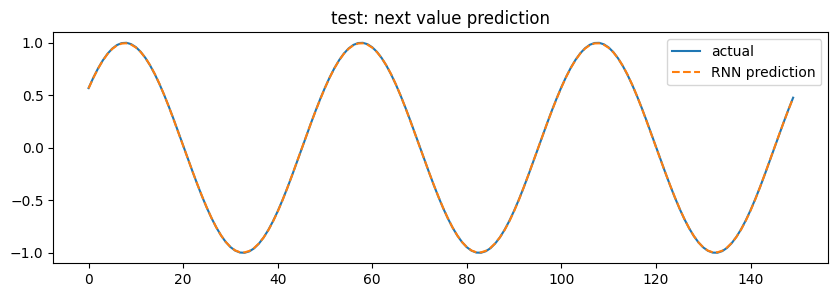

In [5]:
model.eval()
with torch.no_grad():
    pred = model(X_test)
plt.figure(figsize=(10, 3))
plt.plot(y_test[:150], label="actual")
plt.plot(pred[:150], "--", label="RNN prediction")
plt.legend(); plt.title("test: next value prediction"); plt.show()

## 5. 문제: 코드를 직접 고쳐 보기
1. `WINDOW`를 5, 50으로 바꿔서 test MSE를 비교하기. 너무 짧으면 왜 불리할까?
2. `hidden`을 2, 64로 바꾸고 파라미터 수와 test MSE 비교하기.
3. `wave = torch.sin(t) + 0.1 * torch.randn(1000)` (잡음 추가)으로 바꾸면 예측 그래프가 어떻게 달라질까?
4. `forward`에서 `out[:, -1, :]` 대신 `h_n[0]`을 써도 결과가 같은 이유는?
5. 학습 셀의 에폭 `range(1, 21)`을 5, 50으로 바꾸기. 20보다 많이 하면 계속 좋아질까?
6. 학습률 `lr=0.01`을 0.001, 0.1로 바꾸기. 각각 어떤 문제가 생길까?
7. (도전) 바로 다음 값이 아니라 **5칸 뒤 값**을 예측하도록 `X`, `y` 만드는 줄을 고치기. 더 쉬워질까, 어려워질까?

<details><summary>정답 보기</summary>

1. 실행 결과 예: 20 → 0.00001, 5 → 0.00019, 50 → 0.00009. 5는 보는 범위가 짧아 정보가 부족함. 50은 정보는 많지만 순서가 길어져 학습이 어려워짐 (2일차 "기울기 소실"에서 이유를 다룸). 길수록 무조건 좋은 것은 아님.
2. 파라미터 수 = hidden×1 + hidden×hidden + hidden + hidden + (hidden + 1). hidden 2 → 13개, MSE 약 0.001 (100배 나빠짐). hidden 16 → 321개. hidden 64 → 4,353개, MSE 약 0.000001로 더 좋아짐.
3. MSE 약 0.014. 잡음(표준편차 0.1 → 제곱 0.01)은 예측할 수 없어서 MSE가 0.01 아래로 내려가지 못함. 예측선은 잡음 없는 매끈한 곡선에 가깝게 그려짐.
4. `out`은 모든 시점의 h, `h_n`은 마지막 시점의 h. 층이 1개면 `out[:, -1, :]`와 `h_n[0]`은 같은 값.
5. 실행 결과 예: 5 에폭 0.000057, 20 에폭 0.000008, 50 에폭 0.000009. 20번쯤이면 충분하고 그 뒤로는 거의 같음 (더 한다고 계속 좋아지지 않음).
6. 0.001 → 0.00011 (너무 작아 20 에폭 동안 덜 배움), 0.1 → 0.00086 (너무 커서 최솟값 근처에서 흔들림). 적당한 학습률이 중요.
7. `X = torch.stack([wave[i:i + WINDOW] for i in range(len(wave) - WINDOW - 4)]).unsqueeze(-1)`, `y = wave[WINDOW + 4:].unsqueeze(-1)`. 실행 결과 예: MSE 0.00026으로 다음 값(0.00001)보다 어려워짐. 멀리 볼수록 예측이 어려움.
</details>